# FD004 Paper 2 — UQ-V1 / DS-A with P2-E8 60-cycle backbone

## Objective
Reapply the frozen Paper 1 uncertainty pipeline under DS-A using a **60-cycle P2-E8-style quantile backbone**.

The DS-A data split, held-out regime definition, train-only preprocessing, calibration engines, and test engines remain unchanged.

### UQ model
- input: 60 × 20
- Dense(18, no bias)
- LSTM(64)
- Dense(3) for q10 / q50 / q90
- multi-quantile pinball loss

### Conformal methods
1. Asymmetric CQR
2. Balanced Engine CQR

The calibration engines are **not used to train the quantile model**. This preserves the Paper 1 conformal protocol.


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Imports and constants

In [2]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

DATA_DIR = "/content/drive/MyDrive/CMAPSSData"

RUL_CLIP = 125
WINDOW_SIZE = 60
N_REGIMES = 6

OPERATING_SETTINGS = [
    "setting_1",
    "setting_2",
    "setting_3"
]

SELECTED_SENSORS = [
    "s_2", "s_3", "s_4", "s_7", "s_8", "s_9",
    "s_11", "s_12", "s_13", "s_14",
    "s_15", "s_17", "s_20", "s_21"
]

ALL_RAW_COLS = (
    ["unit_id", "time_cycles"]
    + OPERATING_SETTINGS
    + [f"s_{i}" for i in range(1, 22)]
)

print("DS-A configuration loaded.")
print(f"Seed: {SEED}")
print(f"Number of regimes: {N_REGIMES}")
print(f"Window size: {WINDOW_SIZE}")

OUTPUT_DIR = "/content/drive/MyDrive/FD004_Paper2_Results/UQ_V1_DS_A"
os.makedirs(OUTPUT_DIR, exist_ok=True)


DS-A configuration loaded.
Seed: 42
Number of regimes: 6
Window size: 60


##Load raw FD004 training data


In [3]:

train_path = os.path.join(DATA_DIR, "train_FD004.txt")

train_raw = pd.read_csv(
    train_path,
    sep=r"\s+",
    header=None
)

# C-MAPSS files may contain trailing empty columns
train_raw = train_raw.iloc[:, :len(ALL_RAW_COLS)]
train_raw.columns = ALL_RAW_COLS

print("FD004 training data loaded.")
print("Shape:", train_raw.shape)
print("Number of engines:", train_raw["unit_id"].nunique())

display(train_raw.head())


FD004 training data loaded.
Shape: (61249, 26)
Number of engines: 249


,unit_id,time_cycles,setting_1,setting_2,setting_3,s_1,s_2,s_3,s_4,s_5,...,s_12,s_13,s_14,s_15,s_16,s_17,s_18,s_19,s_20,s_21
0,1,1,42.0049,0.8400,100.0,445.00,549.68,1343.43,1112.93,3.91,...,129.78,2387.99,8074.83,9.3335,0.02,330,2212,100.00,10.62,6.3670
1,1,2,20.0020,0.7002,100.0,491.19,606.07,1477.61,1237.50,9.35,...,312.59,2387.73,8046.13,9.1913,0.02,361,2324,100.00,24.37,14.6552
2,1,3,42.0038,0.8409,100.0,445.00,548.95,1343.12,1117.05,3.91,...,129.62,2387.97,8066.62,9.4007,0.02,329,2212,100.00,10.48,6.4213
3,1,4,42.0000,0.8400,100.0,445.00,548.70,1341.24,1118.03,3.91,...,129.80,2388.02,8076.05,9.3369,0.02,328,2212,100.00,10.54,6.4176
4,1,5,25.0063,0.6207,60.0,462.54,536.10,1255.23,1033.59,7.05,...,164.11,2028.08,7865.80,10.8366,0.02,305,1915,84.93,14.03,8.6754


## Calculate training RUL

In [4]:
max_cycles = (
    train_raw.groupby("unit_id")["time_cycles"]
    .max()
    .rename("max_cycle")
)

train_raw = train_raw.merge(
    max_cycles,
    on="unit_id",
    how="left"
)

train_raw["RUL_raw"] = (
    train_raw["max_cycle"] - train_raw["time_cycles"]
)

train_raw["RUL"] = train_raw["RUL_raw"].clip(
    upper=RUL_CLIP
)

print(train_raw[
    ["unit_id", "time_cycles", "RUL_raw", "RUL"]
].head(10))


   unit_id  time_cycles  RUL_raw  RUL
0        1            1      320  125
1        1            2      319  125
2        1            3      318  125
3        1            4      317  125
4        1            5      316  125
5        1            6      315  125
6        1            7      314  125
7        1            8      313  125
8        1            9      312  125
9        1           10      311  125


## Fit the six operating regimes


In [5]:
setting_scaler = StandardScaler()

settings_scaled = setting_scaler.fit_transform(
    train_raw[OPERATING_SETTINGS]
)

kmeans = KMeans(
    n_clusters=N_REGIMES,
    random_state=SEED,
    n_init=10
)

train_raw["regime"] = kmeans.fit_predict(
    settings_scaled
)

print("Operating regimes assigned.")
print(
    train_raw["regime"]
    .value_counts()
    .sort_index()
)


Operating regimes assigned.
regime
0    15395
1     9224
2     9139
3     9091
4     9238
5     9162
Name: count, dtype: int64


## Create the regime summary

In [6]:
regime_summary = (
    train_raw
    .groupby("regime")
    .agg(
        observations=("unit_id", "size"),
        engines=("unit_id", "nunique"),
        mean_RUL=("RUL", "mean"),
        median_RUL=("RUL", "median"),
        mean_setting_1=("setting_1", "mean"),
        mean_setting_2=("setting_2", "mean"),
        mean_setting_3=("setting_3", "mean")
    )
    .reset_index()
)

regime_summary["observation_pct"] = (
    100
    * regime_summary["observations"]
    / len(train_raw)
)

display(
    regime_summary.round(3)
)


,regime,observations,engines,mean_RUL,median_RUL,mean_setting_1,mean_setting_2,mean_setting_3,observation_pct
0,0,15395,249,92.759,123.0,42.003,0.840,100.0,25.135
1,1,9224,249,93.098,123.0,10.003,0.251,100.0,15.060
2,2,9139,249,93.273,122.0,25.003,0.621,60.0,14.921
3,3,9091,249,93.099,123.0,20.003,0.701,100.0,14.843
4,4,9238,249,92.744,121.0,0.002,0.000,100.0,15.083
5,5,9162,249,93.095,122.0,35.003,0.841,100.0,14.959


## Determine engine/regime overlap


In [7]:
engine_regime_counts = (
    train_raw
    .groupby("unit_id")["regime"]
    .nunique()
)

print("Regimes encountered per engine:")
display(
    engine_regime_counts
    .value_counts()
    .sort_index()
    .rename_axis("number_of_regimes")
    .reset_index(name="number_of_engines")
)

print(
    "\nMedian regimes per engine:",
    engine_regime_counts.median()
)

print(
    "Maximum regimes per engine:",
    engine_regime_counts.max()
)


Regimes encountered per engine:


,number_of_regimes,number_of_engines
0,6,249



Median regimes per engine: 6.0
Maximum regimes per engine: 6


## Set held-out regime


In [8]:
HELD_OUT_REGIME = 0

print(f"DS-A held-out operating regime: {HELD_OUT_REGIME}")

heldout_rows = train_raw[
    train_raw["regime"] == HELD_OUT_REGIME
]

print("Held-out observations:", len(heldout_rows))
print(
    "Percentage of dataset:",
    round(100 * len(heldout_rows) / len(train_raw), 2),
    "%"
)
print(
    "Engines represented:",
    heldout_rows["unit_id"].nunique()
)


DS-A held-out operating regime: 0
Held-out observations: 15395
Percentage of dataset: 25.14 %
Engines represented: 249


## Create engine-level split

In [9]:
from sklearn.model_selection import train_test_split

all_engines = np.array(
    sorted(train_raw["unit_id"].unique())
)

train_engines, temp_engines = train_test_split(
    all_engines,
    test_size=0.30,
    random_state=SEED
)

cal_engines, test_engines = train_test_split(
    temp_engines,
    test_size=0.50,
    random_state=SEED
)

print("Train engines:", len(train_engines))
print("Calibration engines:", len(cal_engines))
print("Test engines:", len(test_engines))

print(
    "\nTotal:",
    len(train_engines)
    + len(cal_engines)
    + len(test_engines)
)


Train engines: 174
Calibration engines: 37
Test engines: 38

Total: 249


## Verify zero engine leakage

In [10]:
assert len(
    set(train_engines) & set(cal_engines)
) == 0

assert len(
    set(train_engines) & set(test_engines)
) == 0

assert len(
    set(cal_engines) & set(test_engines)
) == 0

print("✓ No engine leakage between splits.")


✓ No engine leakage between splits.


## Apply the DS-A regime exclusion

In [11]:
train_ds = train_raw[
    train_raw["unit_id"].isin(train_engines)
].copy()

cal_ds = train_raw[
    train_raw["unit_id"].isin(cal_engines)
].copy()

test_ds = train_raw[
    train_raw["unit_id"].isin(test_engines)
].copy()


# Remove held-out regime from TRAIN
train_ds = train_ds[
    train_ds["regime"] != HELD_OUT_REGIME
].copy()

# Remove held-out regime from CALIBRATION
cal_ds = cal_ds[
    cal_ds["regime"] != HELD_OUT_REGIME
].copy()

# TEST contains only held-out regime observations
test_ds = test_ds[
    test_ds["regime"] == HELD_OUT_REGIME
].copy()


In [12]:
print("TRAIN")
print(train_ds["regime"].value_counts().sort_index())

print("\nCALIBRATION")
print(cal_ds["regime"].value_counts().sort_index())

print("\nTEST")
print(test_ds["regime"].value_counts().sort_index())


TRAIN
regime
1    6409
2    6378
3    6354
4    6491
5    6438
Name: count, dtype: int64

CALIBRATION
regime
1    1385
2    1401
3    1339
4    1347
5    1351
Name: count, dtype: int64

TEST
regime
0    2352
Name: count, dtype: int64


## Hard validation

In [13]:
assert HELD_OUT_REGIME not in train_ds["regime"].unique()
assert HELD_OUT_REGIME not in cal_ds["regime"].unique()

assert set(
    test_ds["regime"].unique()
) == {HELD_OUT_REGIME}

assert set(
    train_ds["unit_id"].unique()
).isdisjoint(
    set(test_ds["unit_id"].unique())
)

assert set(
    cal_ds["unit_id"].unique()
).isdisjoint(
    set(test_ds["unit_id"].unique())
)

print("✓ DS-A split validation passed.")
print("✓ Held-out regime absent from training.")
print("✓ Held-out regime absent from calibration.")
print("✓ Test contains held-out regime only.")
print("✓ Engine-level isolation preserved.")


✓ DS-A split validation passed.
✓ Held-out regime absent from training.
✓ Held-out regime absent from calibration.
✓ Test contains held-out regime only.
✓ Engine-level isolation preserved.


## Fit sensor scaling on eligible training observations only

In [14]:
# ============================================================
# DS-A preprocessing
# Fit sensor scaler using TRAIN ENGINES and NON-HELD-OUT
# endpoint-eligible operating conditions only
# ============================================================

sensor_scaler = StandardScaler()

scaler_fit_df = train_raw[
    (train_raw["unit_id"].isin(train_engines)) &
    (train_raw["regime"] != HELD_OUT_REGIME)
].copy()

sensor_scaler.fit(
    scaler_fit_df[SELECTED_SENSORS]
)

print("Sensor scaler fitted.")
print("Rows used:", len(scaler_fit_df))
print("Engines used:", scaler_fit_df["unit_id"].nunique())


Sensor scaler fitted.
Rows used: 32070
Engines used: 174


## Scale the original trajectories

In [15]:
# Keep complete trajectories intact.
# Only the sensor values are transformed.

trajectory_df = train_raw.copy()

trajectory_df[SELECTED_SENSORS] = sensor_scaler.transform(
    trajectory_df[SELECTED_SENSORS]
)

trajectory_df = trajectory_df.sort_values(
    ["unit_id", "time_cycles"]
).reset_index(drop=True)

print("Full trajectories prepared:", trajectory_df.shape)


Full trajectories prepared: (61249, 30)


## Leakage-safe window function

In [16]:
def create_ds_a_windows(
    df,
    engine_ids,
    endpoint_mode,
    held_out_regime=0,
    window_size=60
):
    """
    Build windows from uninterrupted original engine trajectories.

    endpoint_mode:
        'seen'    -> endpoint regime must NOT be held out
        'heldout' -> endpoint regime MUST be held out

    Returns
    -------
    X_sensors : (N, window_size, 14)
    X_regimes : (N, window_size)
    y         : (N,)
    ids       : (N,)
    cycles    : endpoint cycle for each window
    endpoint_regimes : regime at prediction endpoint
    """

    X_sensors = []
    X_regimes = []
    y = []
    ids = []
    cycles = []
    endpoint_regimes = []

    for engine_id in sorted(engine_ids):

        eng = (
            df[df["unit_id"] == engine_id]
            .sort_values("time_cycles")
            .reset_index(drop=True)
        )

        if len(eng) < window_size:
            continue

        for end_idx in range(window_size - 1, len(eng)):

            start_idx = end_idx - window_size + 1

            window = eng.iloc[start_idx:end_idx + 1]

            endpoint_regime = int(
                eng.iloc[end_idx]["regime"]
            )

            # Eligibility depends ONLY on prediction endpoint
            if endpoint_mode == "seen":
                if endpoint_regime == held_out_regime:
                    continue

            elif endpoint_mode == "heldout":
                if endpoint_regime != held_out_regime:
                    continue

            else:
                raise ValueError(
                    "endpoint_mode must be 'seen' or 'heldout'"
                )

            # Ensure cycles are genuinely consecutive
            cycle_values = window["time_cycles"].to_numpy()

            if not np.all(np.diff(cycle_values) == 1):
                raise ValueError(
                    f"Non-consecutive window detected "
                    f"for engine {engine_id}"
                )

            X_sensors.append(
                window[SELECTED_SENSORS].to_numpy(
                    dtype=np.float32
                )
            )

            X_regimes.append(
                window["regime"].to_numpy(
                    dtype=np.int32
                )
            )

            y.append(
                float(eng.iloc[end_idx]["RUL"])
            )

            ids.append(engine_id)

            cycles.append(
                int(eng.iloc[end_idx]["time_cycles"])
            )

            endpoint_regimes.append(
                endpoint_regime
            )

    return (
        np.asarray(X_sensors, dtype=np.float32),
        np.asarray(X_regimes, dtype=np.int32),
        np.asarray(y, dtype=np.float32),
        np.asarray(ids, dtype=np.int32),
        np.asarray(cycles, dtype=np.int32),
        np.asarray(endpoint_regimes, dtype=np.int32)
    )


## Construct train, calibration and DS-A test windows

In [17]:
(
    X_train_sensors,
    reg_train,
    y_train_ds,
    ids_train,
    cycles_train,
    reg_train_endpoint
) = create_ds_a_windows(
    trajectory_df,
    train_engines,
    endpoint_mode="seen",
    held_out_regime=HELD_OUT_REGIME,
    window_size=WINDOW_SIZE
)


(
    X_cal_sensors,
    reg_cal,
    y_cal_ds,
    ids_cal,
    cycles_cal,
    reg_cal_endpoint
) = create_ds_a_windows(
    trajectory_df,
    cal_engines,
    endpoint_mode="seen",
    held_out_regime=HELD_OUT_REGIME,
    window_size=WINDOW_SIZE
)


(
    X_test_sensors,
    reg_test,
    y_test_ds,
    ids_test,
    cycles_test,
    reg_test_endpoint
) = create_ds_a_windows(
    trajectory_df,
    test_engines,
    endpoint_mode="heldout",
    held_out_regime=HELD_OUT_REGIME,
    window_size=WINDOW_SIZE
)


print("TRAIN:", X_train_sensors.shape, y_train_ds.shape)
print("CAL  :", X_cal_sensors.shape, y_cal_ds.shape)
print("TEST :", X_test_sensors.shape, y_test_ds.shape)


TRAIN: (24429, 60, 14) (24429,)
CAL  : (5167, 60, 14) (5167,)
TEST : (1753, 60, 14) (1753,)


## Validate the windows

In [18]:
print("Train endpoint regimes:",
      np.unique(reg_train_endpoint))

print("Calibration endpoint regimes:",
      np.unique(reg_cal_endpoint))

print("Test endpoint regimes:",
      np.unique(reg_test_endpoint))


assert HELD_OUT_REGIME not in np.unique(
    reg_train_endpoint
)

assert HELD_OUT_REGIME not in np.unique(
    reg_cal_endpoint
)

assert set(
    np.unique(reg_test_endpoint)
) == {HELD_OUT_REGIME}


assert set(ids_train).isdisjoint(
    set(ids_cal)
)

assert set(ids_train).isdisjoint(
    set(ids_test)
)

assert set(ids_cal).isdisjoint(
    set(ids_test)
)

assert X_train_sensors.shape[1] == WINDOW_SIZE
assert X_cal_sensors.shape[1] == WINDOW_SIZE
assert X_test_sensors.shape[1] == WINDOW_SIZE

print("\n✓ Window construction passed.")
print("✓ No engine leakage.")
print("✓ Train/cal endpoints exclude held-out regime.")
print("✓ Test endpoints contain held-out regime only.")
print("✓ Every sequence contains 60 consecutive cycles.")


Train endpoint regimes: [1 2 3 4 5]
Calibration endpoint regimes: [1 2 3 4 5]
Test endpoint regimes: [0]

✓ Window construction passed.
✓ No engine leakage.
✓ Train/cal endpoints exclude held-out regime.
✓ Test endpoints contain held-out regime only.
✓ Every sequence contains 60 consecutive cycles.


In [19]:
import tensorflow as tf

reg_train_oh = tf.keras.utils.to_categorical(
    reg_train,
    num_classes=N_REGIMES
)

reg_cal_oh = tf.keras.utils.to_categorical(
    reg_cal,
    num_classes=N_REGIMES
)

reg_test_oh = tf.keras.utils.to_categorical(
    reg_test,
    num_classes=N_REGIMES
)

X_train_ds = np.concatenate(
    [X_train_sensors, reg_train_oh],
    axis=-1
)

X_cal_ds = np.concatenate(
    [X_cal_sensors, reg_cal_oh],
    axis=-1
)

X_test_ds = np.concatenate(
    [X_test_sensors, reg_test_oh],
    axis=-1
)

print("Final model inputs:")
print("Train:", X_train_ds.shape)
print("Cal  :", X_cal_ds.shape)
print("Test :", X_test_ds.shape)

assert X_train_ds.shape[-1] == 20

print("✓ 14 sensor channels + 6 regime channels = 20 features.")


Final model inputs:
Train: (24429, 60, 20)
Cal  : (5167, 60, 20)
Test : (1753, 60, 20)
✓ 14 sensor channels + 6 regime channels = 20 features.


## Fixed experiment settings

In [20]:
import os
import random
import numpy as np
import tensorflow as tf

from tensorflow.keras.layers import Input, Dense, LSTM, Bidirectional, Layer
from tensorflow.keras.models import Model

SEED = 42
ALPHA = 0.20
QUANTILES = [0.10, 0.50, 0.90]

EPOCHS = 60
BATCH_SIZE = 64

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

set_seed(SEED)

print("DS-A model configuration")
print("Seed:", SEED)
print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Target coverage:", 100 * (1 - ALPHA), "%")

DS-A model configuration
Seed: 42
Epochs: 60
Batch size: 64
Target coverage: 80.0 %


## Frozen temporal-attention architecture

In [21]:

class FastTemporalAttention(Layer):

    def __init__(self, **kwargs):
        super().__init__(**kwargs)

    def build(self, input_shape):

        dim = input_shape[-1]

        self.W = self.add_weight(
            name="W",
            shape=(dim, dim),
            initializer="glorot_uniform",
            trainable=True
        )

        self.b = self.add_weight(
            name="b",
            shape=(dim,),
            initializer="zeros",
            trainable=True
        )

        self.v = self.add_weight(
            name="v",
            shape=(dim, 1),
            initializer="glorot_uniform",
            trainable=True
        )

        super().build(input_shape)

    def call(self, inputs):

        e = tf.nn.tanh(
            tf.tensordot(inputs, self.W, axes=1)
            + self.b
        )

        scores = tf.tensordot(
            e,
            self.v,
            axes=1
        )

        weights = tf.nn.softmax(
            scores,
            axis=1
        )

        return tf.reduce_sum(
            inputs * weights,
            axis=1
        )

## Quantile loss

In [22]:
def tilted_loss(q, y_true, y_pred):

    error = y_true - y_pred

    return tf.maximum(
        q * error,
        (q - 1.0) * error
    )


def multi_quantile_pinball_loss(
    y_true,
    y_pred
):

    y_true = tf.cast(
        tf.reshape(y_true, (-1, 1)),
        tf.float32
    )

    losses = []

    for i, q in enumerate(QUANTILES):

        losses.append(
            tilted_loss(
                q,
                y_true,
                y_pred[:, i:i+1]
            )
        )

    return tf.reduce_mean(
        tf.add_n(losses)
    )


## Build the frozen Paper 1 model

In [23]:
def build_ds_a_model():

    inputs = Input(
        shape=(WINDOW_SIZE, 20),
        name="input_window"
    )

    x = Dense(
        18,
        use_bias=False,
        name="projection"
    )(inputs)

    x = LSTM(
        64,
        return_sequences=False,
        name="lstm_core"
    )(x)

    outputs = Dense(
        3,
        activation="linear",
        name="quantiles"
    )(x)

    model = Model(
        inputs=inputs,
        outputs=outputs,
        name="P2_E8_UQ_DS_A_60cycle"
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss=multi_quantile_pinball_loss
    )

    return model

model = build_ds_a_model()
model.summary()


Model: "P2_E8_UQ_DS_A_60cycle"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_window (InputLayer)       │ (None, 60, 20)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ projection (Dense)              │ (None, 60, 18)         │           360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_core (LSTM)                │ (None, 64)             │        21,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ quantiles (Dense)               │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,803 (85.17 KB)

 Trainable params: 21,803 (85.17 KB)

 Non-trainable params: 0 (0.00 B)

## Train the model

In [24]:
set_seed(SEED)

history = model.fit(
    X_train_ds,
    y_train_ds,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=2,
    shuffle=True
)


Epoch 1/60
382/382 - 6s - 17ms/step - loss: 100.4611
Epoch 2/60
382/382 - 2s - 6ms/step - loss: 74.1582
Epoch 3/60
382/382 - 3s - 8ms/step - loss: 56.8436
Epoch 4/60
382/382 - 3s - 8ms/step - loss: 45.0253
Epoch 5/60
382/382 - 2s - 6ms/step - loss: 37.1394
Epoch 6/60
382/382 - 2s - 6ms/step - loss: 31.9152
Epoch 7/60
382/382 - 2s - 6ms/step - loss: 30.0003
Epoch 8/60
382/382 - 3s - 7ms/step - loss: 29.9752
Epoch 9/60
382/382 - 4s - 10ms/step - loss: 29.9708
Epoch 10/60
382/382 - 2s - 6ms/step - loss: 29.9657
Epoch 11/60
382/382 - 2s - 6ms/step - loss: 29.9701
Epoch 12/60
382/382 - 2s - 6ms/step - loss: 26.2805
Epoch 13/60
382/382 - 2s - 6ms/step - loss: 17.6077
Epoch 14/60
382/382 - 3s - 9ms/step - loss: 13.1820
Epoch 15/60
382/382 - 3s - 7ms/step - loss: 11.3970
Epoch 16/60
382/382 - 2s - 6ms/step - loss: 10.6835
Epoch 17/60
382/382 - 2s - 6ms/step - loss: 10.0657
Epoch 18/60
382/382 - 2s - 6ms/step - loss: 9.7441
Epoch 19/60
382/382 - 3s - 8ms/step - loss: 9.5027
Epoch 20/60
382/382 

## Generate calibration and held-out predictions

In [25]:
cal_predictions = model.predict(
    X_cal_ds,
    batch_size=512,
    verbose=0
)

test_predictions = model.predict(
    X_test_ds,
    batch_size=512,
    verbose=0
)

print(
    "Calibration predictions:",
    cal_predictions.shape
)

print(
    "DS-A predictions:",
    test_predictions.shape
)


p10_cal_raw = cal_predictions[:, 0]
p50_cal = cal_predictions[:, 1]
p90_cal_raw = cal_predictions[:, 2]

p10_test_raw = test_predictions[:, 0]
p50_test = test_predictions[:, 1]
p90_test_raw = test_predictions[:, 2]


Calibration predictions: (5167, 3)
DS-A predictions: (1753, 3)


## First point-prediction result

In [26]:
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error
)

test_rmse = np.sqrt(
    mean_squared_error(
        y_test_ds,
        p50_test
    )
)

test_mae = mean_absolute_error(
    y_test_ds,
    p50_test
)

print("=" * 60)
print("DS-A POINT PREDICTION")
print("=" * 60)

print(f"RMSE : {test_rmse:.3f}")
print(f"MAE  : {test_mae:.3f}")
print(f"Test windows : {len(y_test_ds)}")
print(
    "Test engines :",
    len(np.unique(ids_test))
)


DS-A POINT PREDICTION
RMSE : 18.388
MAE  : 12.742
Test windows : 1753
Test engines : 38


# Asymmetric CQR
##Conformal quantile helper


In [27]:
def conformal_quantile(
    scores,
    alpha
):

    scores = np.asarray(scores)

    n = len(scores)

    q_level = np.ceil(
        (n + 1) * (1 - alpha)
    ) / n

    q_level = min(
        1.0,
        q_level
    )

    return float(
        np.quantile(
            scores,
            q_level,
            method="higher"
        )
    )


## Asymmetric CQR calibration

In [28]:
lower_scores = (
    p10_cal_raw - y_cal_ds
)

upper_scores = (
    y_cal_ds - p90_cal_raw
)

q_hat_lower = conformal_quantile(
    lower_scores,
    ALPHA / 2
)

q_hat_upper = conformal_quantile(
    upper_scores,
    ALPHA / 2
)

print(
    "Asymmetric CQR corrections:"
)

print(
    f"Q lower = {q_hat_lower:.3f}"
)

print(
    f"Q upper = {q_hat_upper:.3f}"
)

Asymmetric CQR corrections:
Q lower = 6.870
Q upper = 6.449


##  Apply Asymmetric CQR to DS-A

In [29]:
asym_lower = np.maximum(
    0.0,
    p10_test_raw - q_hat_lower
)

asym_upper = np.maximum(
    0.0,
    p90_test_raw + q_hat_upper
)

asym_covered = (
    (y_test_ds >= asym_lower) &
    (y_test_ds <= asym_upper)
)

asym_picp = (
    100 * asym_covered.mean()
)

asym_mpiw = np.mean(
    asym_upper - asym_lower
)

print("=" * 60)
print("DS-A ASYMMETRIC CQR")
print("=" * 60)

print(
    f"Coverage : {asym_picp:.2f}%"
)

print(
    f"Mean width: {asym_mpiw:.3f}"
)

print(
    f"Target    : {100*(1-ALPHA):.1f}%"
)


DS-A ASYMMETRIC CQR
Coverage : 69.71%
Mean width: 26.385
Target    : 80.0%


#  Balanced Engine CQR
## Calibration error by engine

In [30]:
cal_errors = np.maximum(
    p10_cal_raw - y_cal_ds,
    y_cal_ds - p90_cal_raw
)

calibration_engines = np.unique(
    ids_cal
)

engine_q80_errors = []

for eng in calibration_engines:

    mask = ids_cal == eng

    engine_q80_errors.append(
        np.quantile(
            cal_errors[mask],
            0.80
        )
    )

engine_q80_errors = np.asarray(
    engine_q80_errors
)

print(
    "Calibration engines:",
    len(calibration_engines)
)

print(
    "Engine q80 values:",
    engine_q80_errors.shape
)


Calibration engines: 37
Engine q80 values: (37,)


## Balanced Engine correction

In [31]:
n_eng = len(
    calibration_engines
)

q_level_engine = np.ceil(
    (n_eng + 1) *
    (1 - ALPHA)
) / n_eng

q_level_engine = min(
    1.0,
    q_level_engine
)

q_hat_balanced = float(
    np.quantile(
        engine_q80_errors,
        q_level_engine,
        method="higher"
    )
)

print(
    f"Balanced Engine Q_hat = "
    f"{q_hat_balanced:.3f}"
)


Balanced Engine Q_hat = 16.568


## Apply Balanced Engine CQR

In [32]:
balanced_lower = np.maximum(
    0.0,
    p10_test_raw - q_hat_balanced
)

balanced_upper = np.maximum(
    0.0,
    p90_test_raw + q_hat_balanced
)

balanced_covered = (
    (y_test_ds >= balanced_lower) &
    (y_test_ds <= balanced_upper)
)

balanced_picp = (
    100 * balanced_covered.mean()
)

balanced_mpiw = np.mean(
    balanced_upper -
    balanced_lower
)

print("=" * 60)
print("DS-A BALANCED ENGINE CQR")
print("=" * 60)

print(
    f"Coverage  : "
    f"{balanced_picp:.2f}%"
)

print(
    f"Mean width: "
    f"{balanced_mpiw:.3f}"
)

print(
    f"Q_hat     : "
    f"{q_hat_balanced:.3f}"
)


DS-A BALANCED ENGINE CQR
Coverage  : 85.05%
Mean width: 45.342
Q_hat     : 16.568


## First DS-A comparison table

In [33]:
ds_a_summary = pd.DataFrame([
    {
        "Method":
            "Asymmetric CQR",

        "RMSE":
            test_rmse,

        "MAE":
            test_mae,

        "Coverage":
            asym_picp,

        "Mean_Width":
            asym_mpiw,
    },

    {
        "Method":
            "Balanced Engine CQR",

        "RMSE":
            test_rmse,

        "MAE":
            test_mae,

        "Coverage":
            balanced_picp,

        "Mean_Width":
            balanced_mpiw,
    }
])

display(
    ds_a_summary.round(3)
)


,Method,RMSE,MAE,Coverage,Mean_Width
0,Asymmetric CQR,18.388,12.742,69.709,26.385000
1,Balanced Engine CQR,18.388,12.742,85.054,45.341999


In [34]:
# ============================================================
# DS-A PER-ENGINE RELIABILITY
# ============================================================

engine_results = []

for eng in np.unique(ids_test):

    mask = ids_test == eng

    n_windows = np.sum(mask)

    asym_engine_coverage = (
        100 * np.mean(asym_covered[mask])
    )

    balanced_engine_coverage = (
        100 * np.mean(balanced_covered[mask])
    )

    asym_engine_width = np.mean(
        asym_upper[mask] -
        asym_lower[mask]
    )

    balanced_engine_width = np.mean(
        balanced_upper[mask] -
        balanced_lower[mask]
    )

    engine_rmse = np.sqrt(
        mean_squared_error(
            y_test_ds[mask],
            p50_test[mask]
        )
    )

    engine_mae = mean_absolute_error(
        y_test_ds[mask],
        p50_test[mask]
    )

    engine_results.append({
        "engine_id": int(eng),
        "n_windows": int(n_windows),

        "RMSE": engine_rmse,
        "MAE": engine_mae,

        "Asym_Coverage":
            asym_engine_coverage,

        "Asym_Width":
            asym_engine_width,

        "Balanced_Coverage":
            balanced_engine_coverage,

        "Balanced_Width":
            balanced_engine_width
    })


engine_results = pd.DataFrame(
    engine_results
)

display(
    engine_results
    .sort_values("Balanced_Coverage")
    .round(3)
)

,engine_id,n_windows,RMSE,MAE,Asym_Coverage,Asym_Width,Balanced_Coverage,Balanced_Width
9,105,34,28.926,27.001,8.824,31.364000,44.118,50.445999
27,184,69,38.286,28.663,47.826,25.416000,52.174,43.844002
13,115,21,32.693,28.085,9.524,28.889999,57.143,48.244999
26,181,18,30.716,24.583,38.889,27.902000,61.111,45.874001
2,26,50,24.022,18.781,46.000,29.636999,62.000,48.478001
0,17,19,26.489,20.383,73.684,29.146999,73.684,47.648998
20,140,56,16.830,12.958,55.357,24.305000,76.786,43.152000
4,34,48,19.073,13.723,39.583,26.301001,77.083,44.962002
30,200,49,19.822,14.745,69.388,25.332001,77.551,44.141998
5,39,37,21.526,14.337,70.270,25.370001,78.378,43.341999


In [35]:
TARGET = 80.0

engine_summary = pd.DataFrame({
    "Metric": [
        "Number of test engines",
        "Asymmetric engines >= target",
        "Balanced engines >= target",
        "Asymmetric worst-engine coverage",
        "Balanced worst-engine coverage",
        "Asymmetric median engine coverage",
        "Balanced median engine coverage"
    ],

    "Value": [
        len(engine_results),

        np.sum(
            engine_results["Asym_Coverage"]
            >= TARGET
        ),

        np.sum(
            engine_results["Balanced_Coverage"]
            >= TARGET
        ),

        engine_results[
            "Asym_Coverage"
        ].min(),

        engine_results[
            "Balanced_Coverage"
        ].min(),

        engine_results[
            "Asym_Coverage"
        ].median(),

        engine_results[
            "Balanced_Coverage"
        ].median()
    ]
})

display(engine_summary.round(3))

,Metric,Value
0,Number of test engines,38.000
1,Asymmetric engines >= target,10.000
2,Balanced engines >= target,26.000
3,Asymmetric worst-engine coverage,8.824
4,Balanced worst-engine coverage,44.118
5,Asymmetric median engine coverage,72.146
6,Balanced median engine coverage,86.842


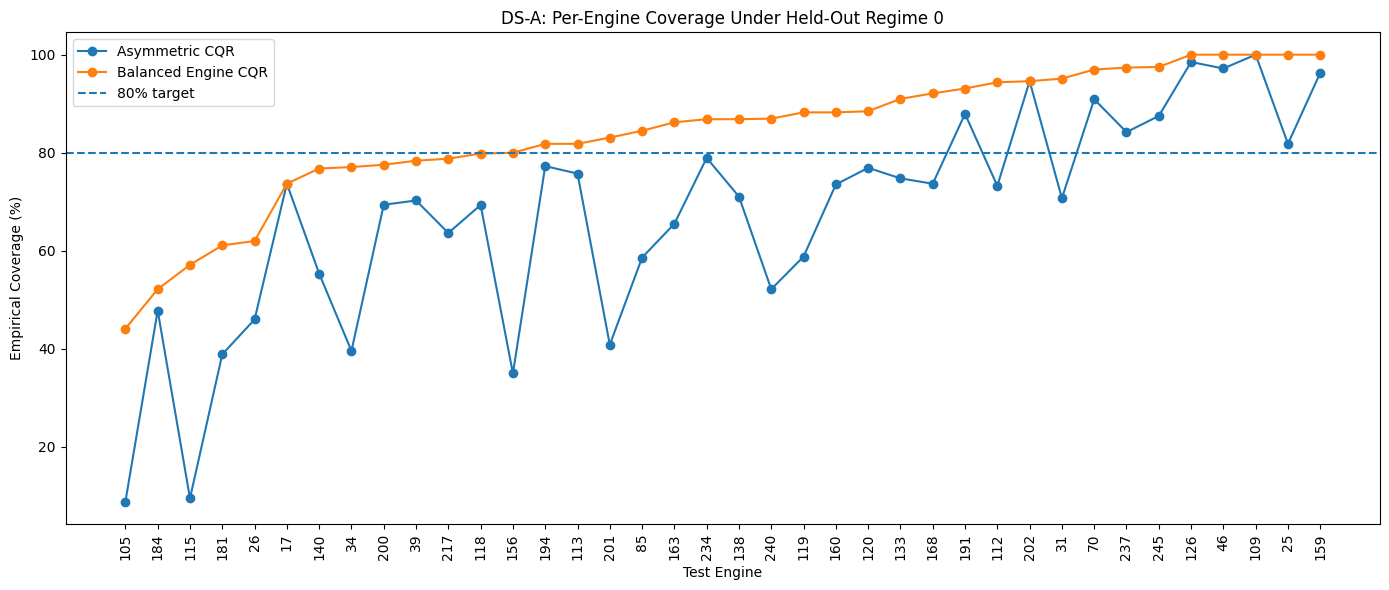

In [36]:
plot_df = (
    engine_results
    .sort_values("Balanced_Coverage")
    .reset_index(drop=True)
)

x = np.arange(len(plot_df))

plt.figure(figsize=(14, 6))

plt.plot(
    x,
    plot_df["Asym_Coverage"],
    marker="o",
    label="Asymmetric CQR"
)

plt.plot(
    x,
    plot_df["Balanced_Coverage"],
    marker="o",
    label="Balanced Engine CQR"
)

plt.axhline(
    80,
    linestyle="--",
    label="80% target"
)

plt.xticks(
    x,
    plot_df["engine_id"],
    rotation=90
)

plt.xlabel("Test Engine")
plt.ylabel("Empirical Coverage (%)")

plt.title(
    "DS-A: Per-Engine Coverage Under Held-Out Regime 0"
)

plt.legend()
plt.tight_layout()
plt.show()

In [37]:
# ============================================================
# DS-A: RELATIONSHIP BETWEEN POINT ERROR AND COVERAGE
# ============================================================

problem_engines = (
    engine_results[
        engine_results["Balanced_Coverage"] < 80
    ]
    .sort_values("Balanced_Coverage")
    .copy()
)

print("Problem engines:", len(problem_engines))

display(
    problem_engines[
        [
            "engine_id",
            "n_windows",
            "RMSE",
            "MAE",
            "Asym_Coverage",
            "Balanced_Coverage",
            "Balanced_Width"
        ]
    ].round(3)
)


Problem engines: 12


,engine_id,n_windows,RMSE,MAE,Asym_Coverage,Balanced_Coverage,Balanced_Width
9,105,34,28.926,27.001,8.824,44.118,50.445999
27,184,69,38.286,28.663,47.826,52.174,43.844002
13,115,21,32.693,28.085,9.524,57.143,48.244999
26,181,18,30.716,24.583,38.889,61.111,45.874001
2,26,50,24.022,18.781,46.000,62.000,48.478001
0,17,19,26.489,20.383,73.684,73.684,47.648998
20,140,56,16.830,12.958,55.357,76.786,43.152000
4,34,48,19.073,13.723,39.583,77.083,44.962002
30,200,49,19.822,14.745,69.388,77.551,44.141998
5,39,37,21.526,14.337,70.270,78.378,43.341999


In [38]:
rmse_cov_corr = engine_results[
    ["RMSE", "Balanced_Coverage"]
].corr().iloc[0, 1]

mae_cov_corr = engine_results[
    ["MAE", "Balanced_Coverage"]
].corr().iloc[0, 1]

print(
    f"RMSE vs Balanced coverage correlation: "
    f"{rmse_cov_corr:.3f}"
)

print(
    f"MAE vs Balanced coverage correlation: "
    f"{mae_cov_corr:.3f}"
)

RMSE vs Balanced coverage correlation: -0.919
MAE vs Balanced coverage correlation: -0.918


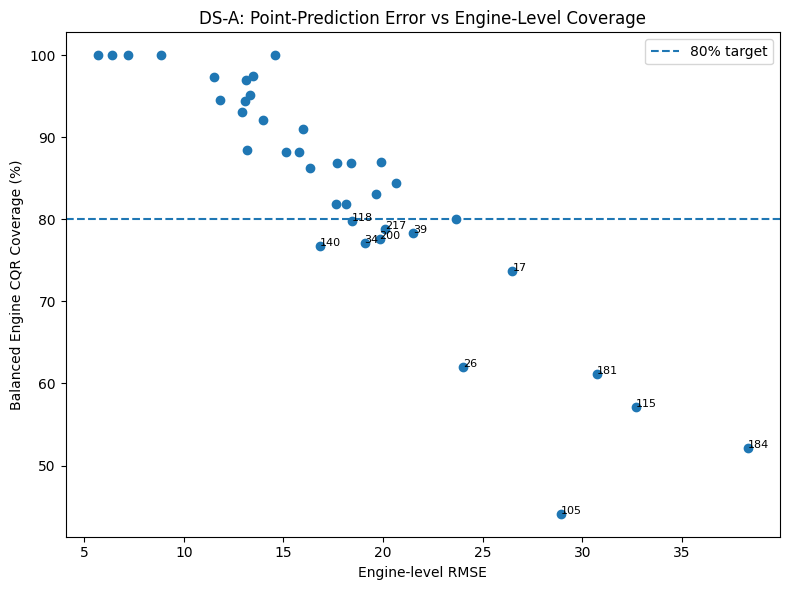

In [39]:
plt.figure(figsize=(8, 6))

plt.scatter(
    engine_results["RMSE"],
    engine_results["Balanced_Coverage"]
)

plt.axhline(
    80,
    linestyle="--",
    label="80% target"
)

for _, row in problem_engines.iterrows():
    plt.annotate(
        str(int(row["engine_id"])),
        (
            row["RMSE"],
            row["Balanced_Coverage"]
        ),
        fontsize=8
    )

plt.xlabel("Engine-level RMSE")
plt.ylabel("Balanced Engine CQR Coverage (%)")

plt.title(
    "DS-A: Point-Prediction Error vs Engine-Level Coverage"
)

plt.legend()
plt.tight_layout()
plt.show()

In [40]:
# ============================================================
# DS-A LIFE-STAGE RELIABILITY
# ============================================================

def assign_life_stage(rul):
    if rul > 80:
        return "Early"
    elif rul > 40:
        return "Mid"
    else:
        return "Late"


life_stage = np.array([
    assign_life_stage(r)
    for r in y_test_ds
])


stage_results = []

for stage in ["Early", "Mid", "Late"]:

    mask = life_stage == stage

    if np.sum(mask) == 0:
        continue

    stage_rmse = np.sqrt(
        mean_squared_error(
            y_test_ds[mask],
            p50_test[mask]
        )
    )

    stage_mae = mean_absolute_error(
        y_test_ds[mask],
        p50_test[mask]
    )

    asym_cov = (
        100 * np.mean(
            asym_covered[mask]
        )
    )

    balanced_cov = (
        100 * np.mean(
            balanced_covered[mask]
        )
    )

    asym_width = np.mean(
        asym_upper[mask] -
        asym_lower[mask]
    )

    balanced_width = np.mean(
        balanced_upper[mask] -
        balanced_lower[mask]
    )

    stage_results.append({
        "Life_Stage": stage,
        "N_Windows": int(np.sum(mask)),
        "RMSE": stage_rmse,
        "MAE": stage_mae,
        "Asym_Coverage": asym_cov,
        "Balanced_Coverage": balanced_cov,
        "Asym_Width": asym_width,
        "Balanced_Width": balanced_width
    })


stage_results = pd.DataFrame(
    stage_results
)

display(
    stage_results.round(3)
)


,Life_Stage,N_Windows,RMSE,MAE,Asym_Coverage,Balanced_Coverage,Asym_Width,Balanced_Width
0,Early,967,19.565,13.666,64.012,81.282,25.820000,45.636002
1,Mid,385,22.172,16.681,66.753,81.558,31.648001,51.266998
2,Late,401,9.113,6.729,86.284,97.506,22.693001,38.945000


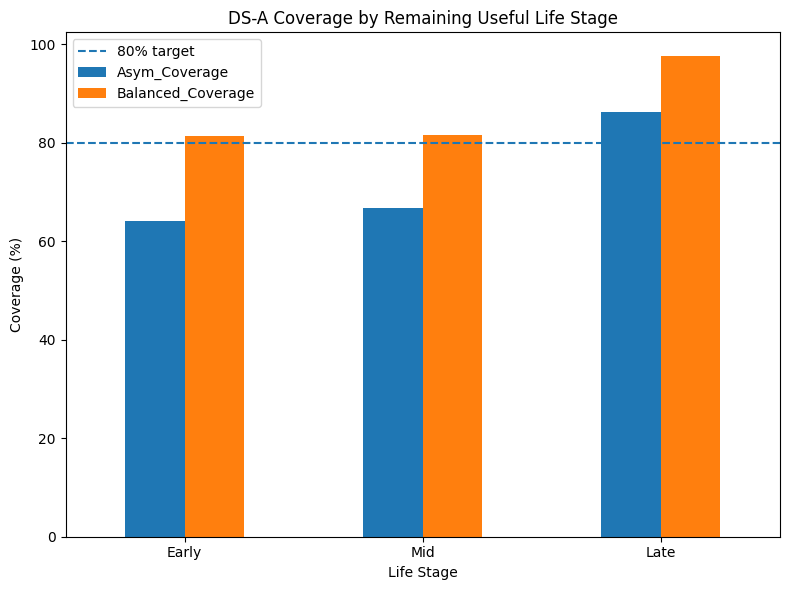

In [41]:
plot_stage = stage_results.set_index(
    "Life_Stage"
)[
    [
        "Asym_Coverage",
        "Balanced_Coverage"
    ]
]

ax = plot_stage.plot(
    kind="bar",
    figsize=(8, 6)
)

ax.axhline(
    80,
    linestyle="--",
    label="80% target"
)

ax.set_ylabel(
    "Coverage (%)"
)

ax.set_xlabel(
    "Life Stage"
)

ax.set_title(
    "DS-A Coverage by Remaining Useful Life Stage"
)

plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()


In [42]:
problem_ids = set(
    problem_engines["engine_id"]
)

problem_mask = np.array([
    eng in problem_ids
    for eng in ids_test
])

problem_stage_summary = []

for stage in ["Early", "Mid", "Late"]:

    mask = (
        problem_mask &
        (life_stage == stage)
    )

    if np.sum(mask) == 0:
        continue

    problem_stage_summary.append({
        "Life_Stage": stage,
        "N_Windows": int(np.sum(mask)),

        "RMSE": np.sqrt(
            mean_squared_error(
                y_test_ds[mask],
                p50_test[mask]
            )
        ),

        "Balanced_Coverage":
            100 * np.mean(
                balanced_covered[mask]
            )
    })


problem_stage_summary = pd.DataFrame(
    problem_stage_summary
)

display(
    problem_stage_summary.round(3)
)


,Life_Stage,N_Windows,RMSE,Balanced_Coverage
0,Early,312,24.812,65.385
1,Mid,123,32.243,58.537
2,Late,123,11.582,93.496


## DS-A with a trajectory diagnostic

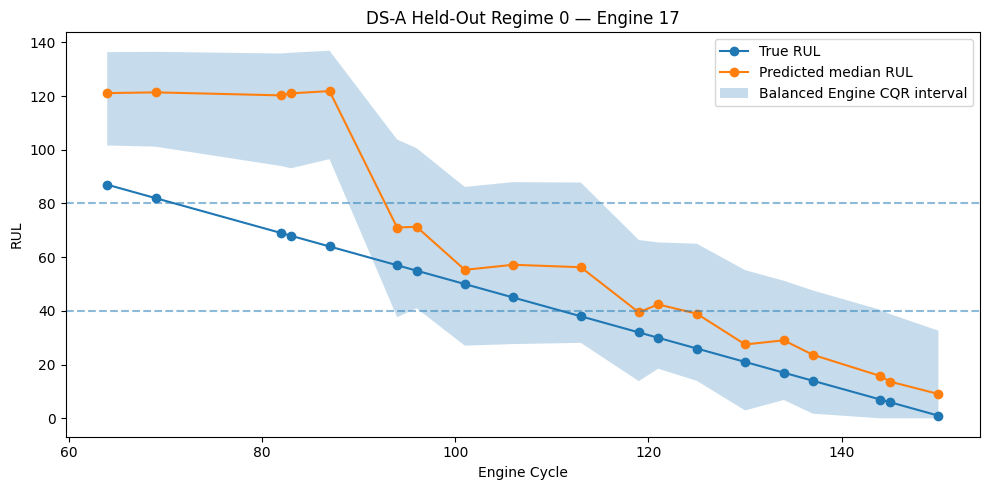

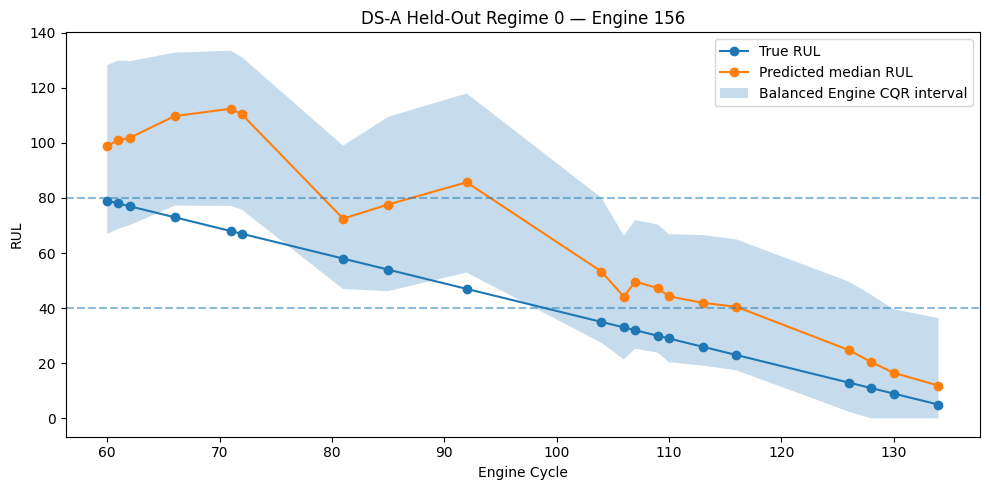

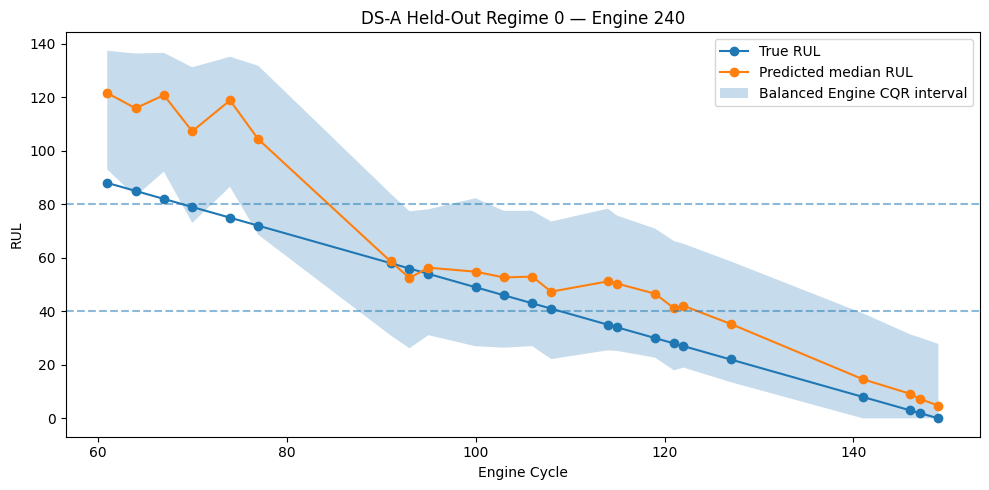

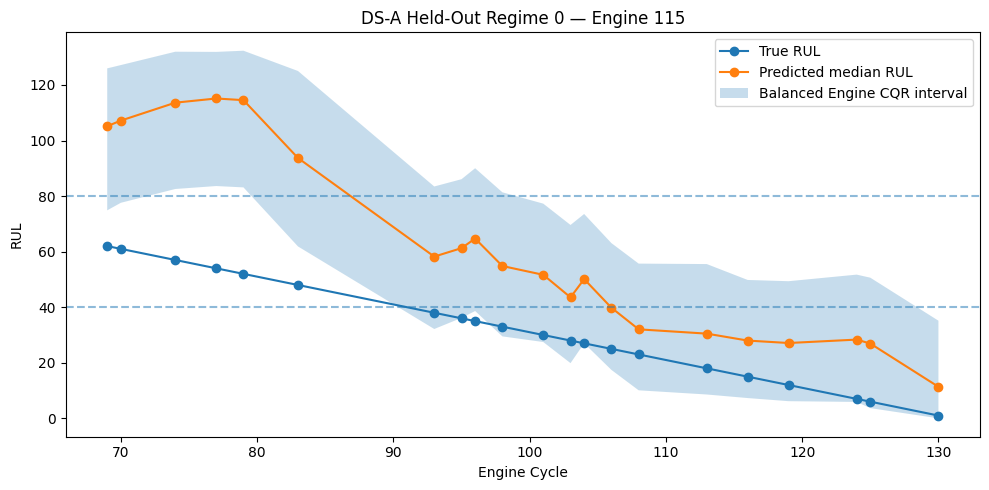

In [43]:
# ============================================================
# DS-A TRAJECTORY DIAGNOSTIC
# Worst-covered engines
# ============================================================

worst_engines = [17, 156, 240, 115]

for eng in worst_engines:

    mask = ids_test == eng

    order = np.argsort(cycles_test[mask])

    cycles_eng = cycles_test[mask][order]
    y_eng = y_test_ds[mask][order]

    pred_eng = p50_test[mask][order]

    lower_eng = balanced_lower[mask][order]
    upper_eng = balanced_upper[mask][order]

    plt.figure(figsize=(10, 5))

    plt.plot(
        cycles_eng,
        y_eng,
        marker="o",
        label="True RUL"
    )

    plt.plot(
        cycles_eng,
        pred_eng,
        marker="o",
        label="Predicted median RUL"
    )

    plt.fill_between(
        cycles_eng,
        lower_eng,
        upper_eng,
        alpha=0.25,
        label="Balanced Engine CQR interval"
    )

    plt.axhline(
        80,
        linestyle="--",
        alpha=0.5
    )

    plt.axhline(
        40,
        linestyle="--",
        alpha=0.5
    )

    plt.xlabel("Engine Cycle")
    plt.ylabel("RUL")

    plt.title(
        f"DS-A Held-Out Regime 0 — Engine {eng}"
    )

    plt.legend()
    plt.tight_layout()
    plt.show()



In [44]:
# ============================================================
# PAPER 2 UQ-V1 / DS-A FINAL SUMMARY + EXPORT
# ============================================================
PERSISTENT_SHIFT_ENGINES = [17, 105, 120, 156, 181, 184, 194, 240, 245]

life_stage = np.where(
    y_test_ds > 80, "Early",
    np.where(y_test_ds > 40, "Mid", "Late")
)

def coverage_summary(mask, method, covered, lower, upper):
    return {
        "Shift": "DS-A",
        "Method": method,
        "Group": "All",
        "Life_Stage": "All",
        "N": int(mask.sum()),
        "Coverage": float(100*np.mean(covered[mask])),
        "Mean_Width": float(np.mean(upper[mask]-lower[mask]))
    }

rows = []
all_mask = np.ones(len(y_test_ds), dtype=bool)

for method, covered, lo, hi in [
    ("Asymmetric CQR", asym_covered, asym_lower, asym_upper),
    ("Balanced Engine CQR", balanced_covered, balanced_lower, balanced_upper),
]:
    rows.append(coverage_summary(all_mask, method, covered, lo, hi))

    for stage in ["Early","Mid","Late"]:
        m = life_stage == stage
        rows.append({
            "Shift":"DS-A","Method":method,"Group":"All","Life_Stage":stage,
            "N":int(m.sum()),
            "Coverage":float(100*np.mean(covered[m])),
            "Mean_Width":float(np.mean(hi[m]-lo[m]))
        })

    persistent_mask = np.isin(ids_test, PERSISTENT_SHIFT_ENGINES)
    for stage in ["All","Mid"]:
        m = persistent_mask if stage=="All" else (persistent_mask & (life_stage=="Mid"))
        if np.any(m):
            rows.append({
                "Shift":"DS-A","Method":method,"Group":"Persistent9","Life_Stage":stage,
                "N":int(m.sum()),
                "Coverage":float(100*np.mean(covered[m])),
                "Mean_Width":float(np.mean(hi[m]-lo[m]))
            })

uq_v1_ds_a_summary = pd.DataFrame(rows)

# Per-engine diagnostics
engine_rows = []
for eng in np.unique(ids_test):
    m = ids_test == eng
    engine_rows.append({
        "Shift":"DS-A",
        "engine_id":int(eng),
        "N":int(m.sum()),
        "Asym_Coverage":float(100*np.mean(asym_covered[m])),
        "Balanced_Coverage":float(100*np.mean(balanced_covered[m])),
        "Asym_Width":float(np.mean(asym_upper[m]-asym_lower[m])),
        "Balanced_Width":float(np.mean(balanced_upper[m]-balanced_lower[m]))
    })

uq_v1_ds_a_engine = pd.DataFrame(engine_rows)

print("\nPAPER 2 UQ-V1 / DS-A SUMMARY")
display(uq_v1_ds_a_summary.round(3))

print("\nENGINE RELIABILITY")
print("Asymmetric engines >=80%:", int((uq_v1_ds_a_engine["Asym_Coverage"]>=80).sum()))
print("Balanced engines >=80%:", int((uq_v1_ds_a_engine["Balanced_Coverage"]>=80).sum()))
print("Asymmetric worst engine:", round(uq_v1_ds_a_engine["Asym_Coverage"].min(),3))
print("Balanced worst engine:", round(uq_v1_ds_a_engine["Balanced_Coverage"].min(),3))

summary_path = os.path.join(OUTPUT_DIR, "UQ_V1_DS_A_summary.csv")
engine_path = os.path.join(OUTPUT_DIR, "UQ_V1_DS_A_engine_metrics.csv")
uq_v1_ds_a_summary.to_csv(summary_path, index=False)
uq_v1_ds_a_engine.to_csv(engine_path, index=False)

print("Saved:", summary_path)
print("Saved:", engine_path)



PAPER 2 UQ-V1 / DS-A SUMMARY


,Shift,Method,Group,Life_Stage,N,Coverage,Mean_Width
0,DS-A,Asymmetric CQR,All,All,1753,69.709,26.385
1,DS-A,Asymmetric CQR,All,Early,967,64.012,25.820
2,DS-A,Asymmetric CQR,All,Mid,385,66.753,31.648
3,DS-A,Asymmetric CQR,All,Late,401,86.284,22.693
4,DS-A,Asymmetric CQR,Persistent9,All,271,54.613,28.402
5,DS-A,Asymmetric CQR,Persistent9,Mid,95,45.263,33.536
6,DS-A,Balanced Engine CQR,All,All,1753,85.054,45.342
7,DS-A,Balanced Engine CQR,All,Early,967,81.282,45.636
8,DS-A,Balanced Engine CQR,All,Mid,385,81.558,51.267
9,DS-A,Balanced Engine CQR,All,Late,401,97.506,38.945



ENGINE RELIABILITY
Asymmetric engines >=80%: 10
Balanced engines >=80%: 26
Asymmetric worst engine: 8.824
Balanced worst engine: 44.118
Saved: /content/drive/MyDrive/FD004_Paper2_Results/UQ_V1_DS_A/UQ_V1_DS_A_summary.csv
Saved: /content/drive/MyDrive/FD004_Paper2_Results/UQ_V1_DS_A/UQ_V1_DS_A_engine_metrics.csv


In [45]:
final_ds_a = pd.DataFrame([
    {
        "Metric": "Point RMSE",
        "Value": test_rmse
    },
    {
        "Metric": "Point MAE",
        "Value": test_mae
    },
    {
        "Metric": "Asymmetric CQR Coverage (%)",
        "Value": asym_picp
    },
    {
        "Metric": "Asymmetric Mean Width",
        "Value": asym_mpiw
    },
    {
        "Metric": "Balanced CQR Coverage (%)",
        "Value": balanced_picp
    },
    {
        "Metric": "Balanced Mean Width",
        "Value": balanced_mpiw
    },
    {
        "Metric": "Balanced engines >= 80%",
        "Value": np.sum(
            engine_results["Balanced_Coverage"] >= 80
        )
    },
    {
        "Metric": "Balanced worst-engine coverage (%)",
        "Value": engine_results[
            "Balanced_Coverage"
        ].min()
    },
    {
        "Metric": "Mid-life Balanced coverage (%)",
        "Value": stage_results.loc[
            stage_results["Life_Stage"] == "Mid",
            "Balanced_Coverage"
        ].iloc[0]
    },
    {
        "Metric": "Problem-engine mid-life coverage (%)",
        "Value": problem_stage_summary.loc[
            problem_stage_summary["Life_Stage"] == "Mid",
            "Balanced_Coverage"
        ].iloc[0]
    }
])

display(final_ds_a.round(3))

,Metric,Value
0,Point RMSE,18.388
1,Point MAE,12.742
2,Asymmetric CQR Coverage (%),69.709
3,Asymmetric Mean Width,26.385
4,Balanced CQR Coverage (%),85.054
5,Balanced Mean Width,45.342
6,Balanced engines >= 80%,26.000
7,Balanced worst-engine coverage (%),44.118
8,Mid-life Balanced coverage (%),81.558
9,Problem-engine mid-life coverage (%),58.537
